# Marginal Model with Missing Values on Americas Subregion Data

This notebook fits the marginal transformation model of the Scalable Composite Transformations (Brachem, Wiemann & Katzfuss, 2026) to data from the Community Earth System (CESM) large ensemble project (Kay et al., 2015). One training response is set to missing to show how `ppptm` masks missing values. The notebook covers only the `ppptm` side; `americas.ipynb` also fits the dependence model.

- Brachem, J., Wiemann, P.F.V., & Katzfuss, M. (2026) Data-Efficient Generative Modeling of Non-Gaussian Global Climate Fields via Scalable Composite Transformations.
- Kay, J. E., Deser, C., Phillips, A., Mai, A., Hannay, C., Strand, G., Arblaster, J. M., Bates, S. C., Danabasoglu, G., Edwards, J., Holland, M., Kushner, P., Lamarque, J.-F., Lawrence, D., Lindsay, K., Middleton, A., Munoz, E., Neale, R., Oleson, K., … Vertenstein, M. (2015). The Community Earth System Model (CESM) large ensemble project: A community resource for studying climate change in the presence of internal climate variability. Bulletin of the American Meteorological Society, 96(8), 1333–1349. https://doi.org/10.1175/BAMS-D-13-00255.1

## Required Software

This project requires Python 3.13.

The library `ppptm` can be installed via 

```
pip install git+https://github.com/jobrachem/ppptm.git
```

For running the Jupyter notebook, you may need to also install `ipykernel` and/or `jupyter`:

```
pip install ipykernel jupyter
```

## Setup

In [1]:
%matplotlib inline

### Library imports

In [2]:
from dataclasses import dataclass
from typing import Literal

import jax
import jax.numpy as jnp
import liesel.goose as gs
import liesel.optim as loptim
import numpy as np
import optax

import ppptm as gptm

jax.config.update("jax_enable_x64", True)

/Users/johannesbrachem/Documents/git/ppptm/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


### Global configuration

For the sake of convenience, we define some globale configuration settings in a dataclass with sensible defaults.

In [3]:
@dataclass
class Config:
    nlocs: int = -1  # -1 means that all locations are being used.
    # Selecting fewer locations can be sensible to reduce runtime and memory usage.

    ntrain: int = 20  # number of samples used for training
    ntest: int = 14  # number of samples used for out-of-sample performance evaluation
    nvalidation: int = 4  # number of validation samples for early stopping
    split_seed: int = 1  # seed for train-validation-test split

    m: int = 64  # number of inducing locations

    # marginal model settings
    G_dist: Literal["gaussian", "skewt"] = "gaussian"  # distribution to be used in G

    H: bool = True  # whether to estimate the semiparametric layer or fix it to identity
    H_a: float = -4.0  # left boundary of onion spline flexible domain
    H_b: float = 4.0  # right boundary of onion spline flexible domain
    H_nparam: int = 40  # number of flexible onion spline parameters ('D' in the paper)

In [4]:
config = Config()

### Data import

In [5]:
data = gptm.load_americas()

In [6]:
# Initialize locations. They are ordered via
# from veccs.orderings2 import farthest_first_ordering
# in the LocationVars.new_from call.
locs = gptm.LocationVars.new_from(data.locs, n_subset=config.m, from_2d_to_3d=True)
y = data.obs[:, locs.locs.ordering]  # apply maximin ordering to data

### Data preprocessing

In [7]:
# ----------------------------------------------------------------------------------
# Data pre-processing
# ----------------------------------------------------------------------------------
rng = np.random.default_rng(config.split_seed)
rng.shuffle(y, axis=0)  # shuffle for train-validation-test-split


if config.nlocs == -1:
    config.nlocs = 2738

# select subset of locations, if not all locations are used
y_model = y[..., : config.nlocs]
locs.ordered.value = locs.locs.ordered[: config.nlocs, ...]
locs_2d = data.locs[locs.locs.ordering, ...][: config.nlocs, ...]

# apply train-validation-test-split
train, validate, test = (
    y_model[: config.ntrain, :],
    y_model[config.ntrain : (config.ntrain + config.nvalidation), :],
    y_model[-config.ntest :, :],
)

# if no validation data should be used, use training data for early stopping
if config.nvalidation == 0:
    validate = train

# z-standardize using global mean and standard deviation of training samples
train_mean = y_model.mean(keepdims=True)
train_sd = y_model.std(keepdims=True)

train = (train - train_mean) / train_sd
validate = (validate - train_mean) / train_sd
test = (test - train_mean) / train_sd

In [8]:
# set one training response to missing; Model masks it with mask_nan_response
train[0, 0] = np.nan

## Marginal model

In [9]:
# ----------------------------------------------------------------------------------
# Marginal model
# ----------------------------------------------------------------------------------

# For some parametric distributions, the class ppptm.G provides convenient constructors.
# If other distributions are desired, the source code of these constructors can be
# used as a template for defining the marginal parametric model.
# The resulting object is a liesel.model.Dist object
match config.G_dist:
    case "gaussian":
        G = gptm.G(train, locs)
        g = G.new_gaussian()
        locscale = True  # in locscale parameterization, computations can be simplified
    case "skewt":
        G = gptm.G(train, locs)
        g = G.new_skewt()
        locscale = False

# set up model
if config.H:  # if we estimate the semiparametric correction H
    marginal_model = gptm.Model.new_HG(
        train,
        locs,
        g_dist=g,
        # 'coef' corresponds to a liesel.model.Var that represents the flexible log
        # increments of the onion spline, called 'beta' in the paper.
        # the class ppptm.H provides a convenient way to initialize a suitable object.
        coef=gptm.H(locs, locwise_amplitude=False).new_coef(),
        locscale=locscale,
        a=config.H_a,
        b=config.H_b,
        nparam=config.H_nparam,
        mask_nan_response=True,
    )
else:  # If we do not estimate the semiparametric correction H
    marginal_model = gptm.Model.new_G(
        train, locs, g, locscale=locscale, mask_nan_response=True
    )

In [10]:
marginal_model.response.value

Array([[        nan,  0.90928792, -2.12416446, ...,  0.70267808,
        -0.51171246, -0.0058912 ],
       [ 1.19809075, -2.12416452, -2.10145609, ...,  1.15423947,
         0.95486124,  1.14417036],
       [ 1.31835619, -0.98571972, -1.66435005, ...,  1.58410255,
         1.31427377,  1.2775824 ],
       ...,
       [ 1.27138269, -2.07180872, -2.12416449, ...,  0.68663139,
         0.67804956,  0.50509118],
       [ 1.5218266 ,  0.1106355 , -2.0557126 , ..., -2.12416309,
        -0.82359032, -0.0315934 ],
       [ 1.21384932, -0.77369733, -2.12416452, ...,  0.2838793 ,
         1.11560801, -0.13003439]], dtype=float64)

In [11]:
# fit model
scheduler = optax.cosine_decay_schedule(init_value=0.001, decay_steps=3_000)
hg_opt = optax.adamw(learning_rate=scheduler, weight_decay=1e-4)
gradient_clipping = optax.clip_by_global_norm(1.0)
marginal_opt = optax.chain(gradient_clipping, hg_opt)

result = marginal_model.fit(
    loss_monitor=(
        "validation"
        if config.nvalidation > 0
        else loptim.EmaTrainLossMonitor(effective_window=1.0)
    ),
    stopper=gs.Stopper(max_iter=3_000, patience=30, atol=0.3),
    response_validation=validate if config.nvalidation > 0 else None,
    optimizer=marginal_opt,
    # when many iterations are used, the progress bar can lead to problems with
    # the jit-compiled execution, so we turn it off here.
    progress_bar=True,
    batch_size=74,
)

# Evaluate marginal transformations for train, validation, and test data
train_hg = marginal_model.hg(train)
validate_hg = marginal_model.hg(validate)
test_hg = marginal_model.hg(test)

Training loss: 43858.272, Monitoring loss: 44216.480:   3%|▎         | 97/3000 [00:06<03:15, 14.83it/s]


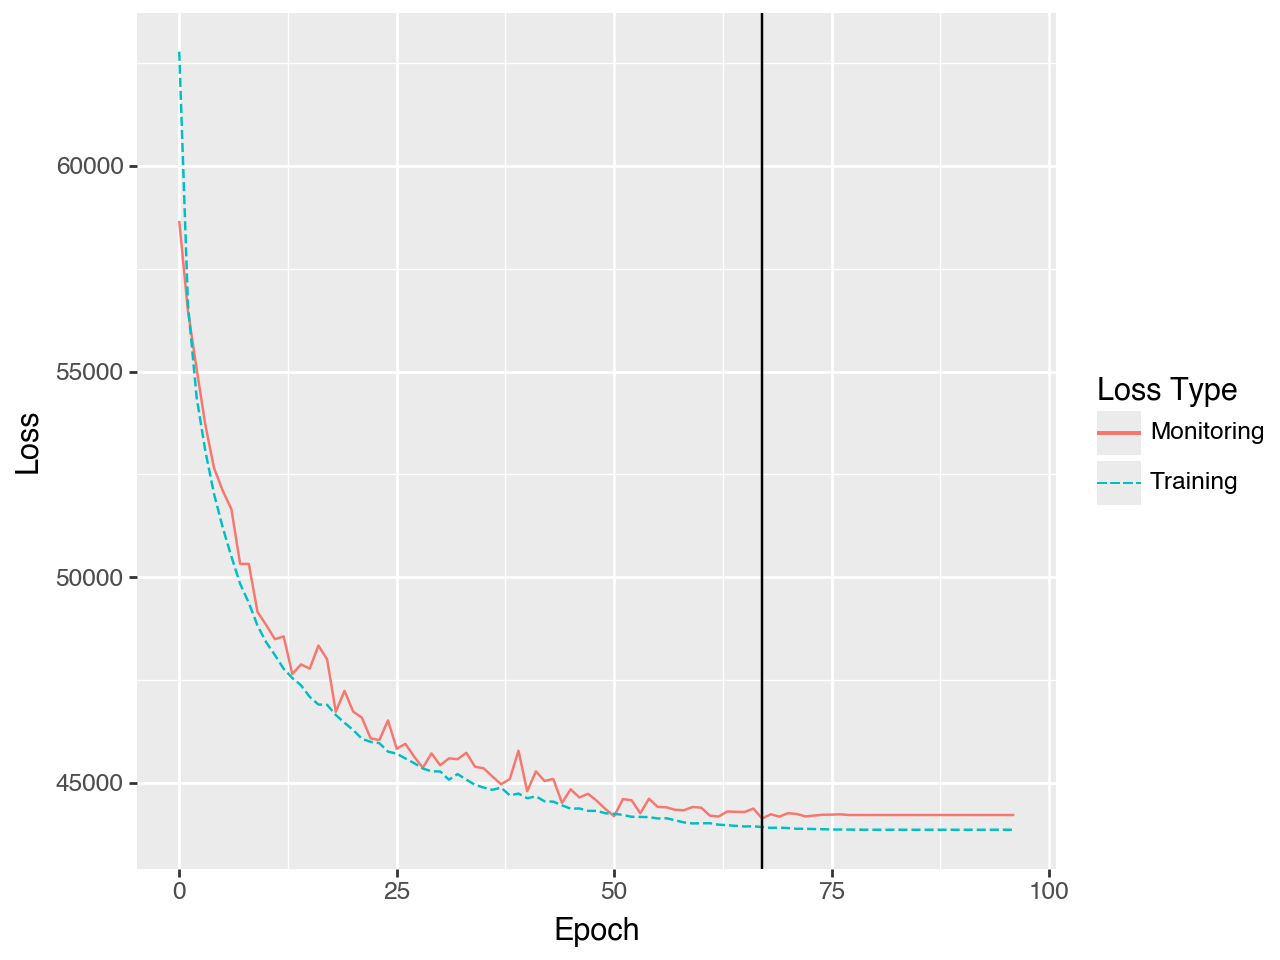

In [12]:
result.plot_loss()

## Transformed data

The missing response stays missing after the transformation. All other responses are transformed as usual.

In [ ]:
print(int(jnp.isnan(train_hg).sum()), "missing value(s) in train_hg")
gptm.plot_df(gptm.long_df(locs_2d, train_hg[:1]))